In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Загружаем данные

In [3]:
for f_name in os.listdir(os.getcwd()):
    if f_name[-4:] == '.csv':
        print(f_name)

value.csv
works.csv
fields.csv


In [4]:
value_ish = pd.read_csv('value.csv', encoding='windows-1251', sep=';', header=2, decimal=',')
value_ish['inv_item_date'] = pd.to_datetime(value_ish['inv_item_date'], format='%d.%m.%Y')

value_ish.head(3)

,field,inv_item_type,inv_item_name,inv_item_weight,inv_item_unit,inv_item_dose,inv_item_date,work_id
0,36.01.21.025.01,Удобрения,Удобрение 31,15017.6,кг,260.0,2024-10-28,E3A7DAEB-D124-4685-ADE1-199818C77361
1,36.14.12.064.00,Удобрения,Удобрение 31,6500.0,м3,65.0,2024-10-28,0AB8C8D7-04BD-4483-98B2-3E062CDD7E3E
2,36.14.16.008.00,Удобрения,Удобрение 49,7865.0,т,65.0,2024-10-28,00E51F81-0A4F-4983-B068-877A089FFD33


In [5]:
works_ish = pd.read_csv('works.csv', encoding='windows-1251', sep=';', header=2, decimal=',')
works_ish['start_date'] = pd.to_datetime(works_ish['start_date'], format='%d.%m.%Y')
works_ish['end_date'] = pd.to_datetime(works_ish['end_date'], format='%d.%m.%Y')
works_ish['area'] = works_ish['area'].str.replace(',', '.').astype('float')

works_ish.head(3)

,season,field,work_type,work_subtype,start_date,end_date,area,main_tech,add_tech,mech,proc_depth,prod_purpose,prod_weight,prod_dry_perc,prod_humid,prod_impur,yield_fact,work_id
0,2023,16.13.12.044.00,Обработка почвы,Боронование,2022-04-29,2022-04-30,49.78,"Трактор колесный Fendt 936 Vario, гос.ном. 050...",Арендованная техника,Ахметсафин Айрат Рафикович,10.0,NaN,0.0,NaN,NaN,NaN,0.0,A06AD38A-5448-40EC-B095-4B8918B4AC10
1,2023,16.13.12.017.00,Обработка почвы,Боронование,2022-05-01,2022-05-02,154.76,"Трактор колесный Птз К-744Р4, гос.ном. 2251АА1...","Борона зубовая Veles АГС-22-2У.М, зав.ном. 789",Ямалетдинов Фарид Расыхович,10.0,NaN,0.0,NaN,NaN,NaN,0.0,62B13DCE-FFB5-4E7A-8F1B-88930BD338EF
2,2023,16.13.12.012.00,Обработка почвы,Боронование,2022-05-02,2022-05-03,40.62,"Трактор колесный Fendt 936 Vario, гос.ном. 050...",Арендованная техника,Мухаметзянов Ринат Айратович,10.0,NaN,0.0,NaN,NaN,NaN,0.0,D5884A6D-4710-4C0A-8E5A-878291B89846


In [6]:
fields_ish = pd.read_csv('fields.csv', encoding='windows-1251', sep=';', header=1, decimal=',', skiprows=[2])

fields_ish.head(3)

,field,region,land_type,fertility_score,season,crop,crop_predecessor,crop_yearold,area,hybrid,reproduction,seed_origin,technology,yield_plan,p2o5,k2o,humus,ph,Unnamed: 18
0,22.47.01.001.01,Алтай,пашня,NaN,2023,Оз.пшеница мягкая,Пар; Яр.пшеница мягкая,NaN,306.22,Скипетр,ЭС,Покупные,минимальная,3.8,243.16,226.93,4.46,5.78,NaN
1,22.47.01.001.02,Алтай,пашня,NaN,2023,Пар,Пар; Яр.пшеница мягкая,NaN,63.16,NaN,NaN,NaN,минимальная,NaN,243.16,226.93,4.46,5.78,NaN
2,22.47.01.002.00,Алтай,пашня,4.0,2023,Пар,Яр.пшеница мягкая,NaN,485.79,NaN,NaN,NaN,NaN,NaN,219.78,204.60,3.85,5.72,NaN


# Проверка качества данных

**нет ли дублей по ключам в связующей таблице**

In [7]:
# базово:
    # дублей в fields_ish по ключам нет
    # на ключах нет разных культур

print(
    fields_ish[['field', 'season']].shape,
    fields_ish[['field', 'season']].drop_duplicates().shape,
    (fields_ish[['field', 'season', 'crop']].value_counts() > 1).sum(),

    sep='\n'
)

f_unique = fields_ish[['field', 'season', 'crop', 'area']] \
    .rename(columns={'area':'goal_area'}) \
    .drop_duplicates()

(16054, 2)
(16054, 2)
0


In [8]:
# пустых полей нет, значит все засеивались?
fields_ish[['field', 'season', 'crop']].isna().sum()

field     0
season    0
crop      0
dtype: int64

**все ли поля засеивались?**

In [9]:
works_ish['work_type'].unique()

array(['Обработка почвы', 'Внесение СЗР', 'Внесение удобрений', 'Сев',
       'Уборка'], dtype=object)

In [10]:
# засеивалось только половина полей
f_plant = f_unique.merge(
    works_ish[works_ish['work_type'] == 'Сев'] \
        .drop_duplicates() \
        .groupby(['field', 'season'], as_index=False) \
        .agg({'area':'sum'}),
    how='inner',
    on=['field', 'season']
)

print(
    f_plant.drop_duplicates().shape,
    f_plant.shape,

    sep='\n'
)

(8318, 5)
(8318, 5)


In [11]:
# есть поля, которые меняли свою площадь от сезона к сезону
test = fields_ish[['field', 'season', 'area']].pivot_table(index='field', columns='season', values='area') \
    .reset_index() \
    .dropna()

test[test[2023] != test[2024]]

season,field,2023,2024
18,02.09.06.004.02,66.52,117.94
20,02.09.06.004.04,51.42,37.91
54,02.09.06.049.00,49.03,49.04
63,02.09.06.063.00,11.74,46.74
64,02.09.06.064.00,310.72,275.72
...,...,...,...
8778,72.22.02.033.00,68.08,87.49
8810,72.22.10.005.00,27.52,75.08
8812,72.22.10.007.00,84.29,105.33
8819,72.22.10.012.00,83.92,109.26


In [12]:
# есть поля, которые засеивали в 2 раза большей площадью - что с ними делать???
f_plant[f_plant['area'] > f_plant['goal_area'] * 1.98]['crop'].value_counts().head(5)

crop
Соя                                               50
Яр.пшеница мягкая                                 47
Кукуруза силос                                    46
Одн.тр.(вика+овёс)с подс.(кл.кр.+тим.корм)корм    20
Люцерна 1 г.ж.корм                                18
Name: count, dtype: int64

In [13]:
# пример:
works_ish[
      # (works_ish['work_type'].isin(['Сев', 'Уборка']))
    (works_ish['field'] == '36.29.07.044.00')
    # & (works_ish['season'] == 2024)
].sort_values('start_date')

# их сеяли в сентябре 2023 и затем в мае 2024
# при этом между посевами уборку урожая не производили

,season,field,work_type,work_subtype,start_date,end_date,area,main_tech,add_tech,mech,proc_depth,prod_purpose,prod_weight,prod_dry_perc,prod_humid,prod_impur,yield_fact,work_id
36954,2023,36.29.07.044.00,Обработка почвы,Дискование,2023-05-16,2023-05-16,5.00,"Трактор колесный John Deere 8330, гос.ном. 638...","Борона дисковая Vaderstad Carrier 820, инв.ном...",Ждамаров Сергей Викторович,5.0,NaN,0.00,NaN,NaN,NaN,0.00,FFD04BEF-55B6-43FF-948A-44D344D8B211
37428,2023,36.29.07.044.00,Внесение СЗР,Обработка СЗР,2023-05-16,2023-05-16,114.65,НЕТ В 1С Опрыскиватель самоходный John Deere R...,NaN,Выборнов Андрей Анатольевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,5838C431-C5DA-4389-8B28-BBBAD8E0F391
39962,2023,36.29.07.044.00,Сев,Сев без внесения удобрений,2023-05-19,2023-05-21,114.00,"Трактор колесный John Deere 8430, гос.ном. 004...","Сеялка зерновая Amity Single Disc 30, инв.ном....",Урамов Анатолий Геннадьевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,F1FFC5E0-7322-4155-B62C-D6622E83E7FC
85511,2024,36.29.07.044.00,Обработка почвы,Дискование,2023-09-14,2023-09-14,38.00,"Трактор колесный Case Magnum 315, гос.ном. 776...","Борона дисковая Vaderstad Carrier 820, инв.ном...",Горлов Иван Васильевич,3.0,NaN,0.00,NaN,NaN,NaN,0.00,F316F33F-8DAC-4A05-86F0-9A4A141FD3EC
85518,2024,36.29.07.044.00,Обработка почвы,Дискование,2023-09-14,2023-09-15,76.65,"Трактор колесный John Deere 8295R, гос.ном. 15...","Борона дисковая Einbock Twister 600, инв.ном. ...",Муковнин Николай Николаевич,5.0,NaN,0.00,NaN,NaN,NaN,0.00,822597C0-3175-4E67-90C8-78854F38EE90
86206,2024,36.29.07.044.00,Сев,Сев с внесением удобрений,2023-09-15,2023-09-16,85.00,"Трактор колесный John Deere 8295R, гос.ном. 15...","Сеялка зерновая Vaderstad Rapid RDA 600C, инв....",Горшков Максим Евгеньевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,71107450-D7E1-4B00-B396-0BB8B9A252EC
86661,2024,36.29.07.044.00,Сев,Сев с внесением удобрений,2023-09-16,2023-09-16,29.65,"Трактор колесный John Deere 8295R, гос.ном. 15...","Сеялка зерновая Vaderstad Rapid RDA 600C, инв....",Ермолов Сергей Николаевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,77ED2B98-4191-4F92-B70F-BCDD228A40B8
101982,2024,36.29.07.044.00,Внесение удобрений,Внесение минеральных удобрений,2024-03-07,2024-03-07,114.65,"Трактор колесный John Deere 6155M, гос.ном. 71...",Разбрасыватель минеральных удобрений Amazone Z...,Неретин Алексей Николаевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,1847FCFF-F3F3-4D8E-BFEF-8D88DB6FA3B4
129486,2024,36.29.07.044.00,Внесение СЗР,Обработка СЗР,2024-05-24,2024-05-24,85.00,НЕТ В 1С Опрыскиватель самоходный John Deere R...,NaN,Филиппов Андрей Викторович,NaN,NaN,0.00,NaN,NaN,NaN,0.00,73E9C233-8ECC-49F0-9D1A-C5ABAE748BD8
130792,2024,36.29.07.044.00,Внесение СЗР,Обработка СЗР,2024-05-26,2024-05-26,29.65,НЕТ В 1С Опрыскиватель самоходный John Deere R...,NaN,Выборнов Андрей Анатольевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,90CA3E9C-53F4-4610-81E4-0880F83182F6


**со всех полей был убран урожай?**

In [14]:
# поля на которых была проведена уборка
f_harvest = works_ish[(works_ish['prod_weight'] > 0) & (works_ish['work_type'] == 'Уборка')] \
    .groupby(['season', 'field'], as_index=False) \
    .agg({'prod_weight':'sum', 'area':'sum'})

In [15]:
# не со всех засеянных полей сняли урожай
f_plant.merge(f_harvest, how='left', on=['field', 'season']).info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8318 entries, 0 to 8317
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   field        8318 non-null   object 
 1   season       8318 non-null   int64  
 2   crop         8318 non-null   object 
 3   goal_area    8318 non-null   float64
 4   area_x       8318 non-null   float64
 5   prod_weight  6854 non-null   float64
 6   area_y       6854 non-null   float64
dtypes: float64(4), int64(1), object(2)
memory usage: 455.0+ KB


In [16]:
# урожай сняли с 53 полей, на которых не сеяли :-(
# с 1464 засеянных полей не снимали урожай
f_unique \
    .merge(f_plant, how='inner', on=['field', 'season']) \
    .merge(f_harvest, how='left', on=['field', 'season']).info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8318 entries, 0 to 8317
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   field        8318 non-null   object 
 1   season       8318 non-null   int64  
 2   crop_x       8318 non-null   object 
 3   goal_area_x  8318 non-null   float64
 4   crop_y       8318 non-null   object 
 5   goal_area_y  8318 non-null   float64
 6   area_x       8318 non-null   float64
 7   prod_weight  6854 non-null   float64
 8   area_y       6854 non-null   float64
dtypes: float64(5), int64(1), object(3)
memory usage: 585.0+ KB


In [17]:
# поля, которые и засеивали, и снимали урожай
f_plant_x_harvest_id = f_unique \
    .merge(f_plant, how='inner', on=['field', 'season', 'crop', 'goal_area']) \
    .merge(f_harvest, how='left', on=['field', 'season']) \
    [['season', 'field', 'crop', 'goal_area']].drop_duplicates()

In [18]:
f_unique \
    .merge(f_plant, how='inner', on=['field', 'season']) \
    .merge(f_harvest, how='left', on=['field', 'season'])

,field,season,crop_x,goal_area_x,crop_y,goal_area_y,area_x,prod_weight,area_y
0,22.47.01.001.01,2023,Оз.пшеница мягкая,306.22,Оз.пшеница мягкая,306.22,306.22,58363.51,306.22
1,22.47.01.003.00,2023,Оз.пшеница мягкая,452.25,Оз.пшеница мягкая,452.25,452.25,1176.84,452.25
2,22.47.01.004.00,2023,Оз.пшеница мягкая,269.64,Оз.пшеница мягкая,269.64,269.64,765.10,269.64
3,22.47.01.006.02,2023,Оз.пшеница мягкая,63.33,Оз.пшеница мягкая,63.33,63.33,138.46,63.33
4,22.47.01.007.02,2023,Оз.пшеница мягкая,85.55,Оз.пшеница мягкая,85.55,85.55,180.25,85.55
...,...,...,...,...,...,...,...,...,...
8313,36.29.07.041.00,2024,Яр.пшеница мягкая,93.99,Яр.пшеница мягкая,93.99,93.99,123256.00,93.99
8314,36.29.07.042.00,2024,Яр.пшеница мягкая,70.48,Яр.пшеница мягкая,70.48,70.48,136850.00,70.40
8315,36.29.07.043.00,2024,Соя,115.70,Соя,115.70,231.40,132.86,115.70
8316,36.29.07.044.00,2024,Соя,114.65,Соя,114.65,229.30,60.12,114.64


**сколько видов осталось растений осталось? можно ли их объединить?**

In [19]:
# ответить на этот вопрос не получилось...
pd.Series(f_plant_x_harvest_id['crop'].unique()).sort_values()

11                                 Горох
80                    Горчица сарептская
13                               Гречиха
86                        Ежа 1 г.ж.сем.
54                                Залежь
                     ...                
1                      Яр.пшеница мягкая
9                     Яр.пшеница твёрдая
34                               Яр.рапс
5                              Яр.ячмень
47    Яр.ячмень с подс.(мн.травосм.корм)
Length: 93, dtype: object

In [20]:
# предлагаю убрать те поля, у которых "мало" наблюдений
f_plant_x_harvest_id['crop'].value_counts().sort_values(ascending=False).head(30)

crop
Кукуруза силос                                     1561
Оз.пшеница мягкая                                   923
Яр.пшеница мягкая                                   749
Соя                                                 746
Кукуруза зерно                                      700
Люцерна 1 г.ж.корм                                  513
Яр.ячмень                                           487
Подсолнечник                                        407
Чечевица                                            168
Чечевица зеленая                                    162
Сах.свекла                                          150
Горох                                               145
Кукуруза корнаж                                     140
Одн.тр.суданская тр.корм.                           119
Лён масличный                                       104
Одн.тр.(вика+овёс)с подс.(кл.кр.+тим.корм)корм       98
Одн.тр.райграс одн.с подс.(кл.кр.+тим.корм)корм      85
Одн.тр.(вика+овёс)корм                     

# Доработка от 28.03.2025

In [21]:
tgt_id = f_plant_x_harvest_id[
    f_plant_x_harvest_id['crop'].isin(
        ['Кукуруза силос']
        # list(f_plant_x_harvest_id['crop'].value_counts().sort_values().tail(5).index)
        # [list(f_plant_x_harvest_id['crop'].value_counts().sort_values().tail(5).index)[2]]
    )
]

In [22]:
tgt_id.head(3)

,season,field,crop,goal_area
17,2023,22.47.05.004.00,Кукуруза силос,316.08
18,2023,22.47.05.005.00,Кукуруза силос,365.03
21,2023,22.47.10.002.00,Кукуруза силос,152.97


In [23]:
tgt_df = tgt_id \
    .merge(
        f_plant[
              (f_plant['area'].between(0, f_plant['goal_area']*1.02))
            | (f_plant['area'] > f_plant['goal_area'] * 1.98)
        ][['field', 'season', 'area']], 
        how='inner', 
        on=['field', 'season']
    ).rename(columns={'area':'plant_area'}) \
    .merge(
        f_harvest[['season', 'field', 'prod_weight']],
        how='inner',
        on=['season', 'field']
    ) \
    .merge(
        fields_ish[['field', 'season', 'region', 'humus', 'ph', 'p2o5', 'k2o']],
        how='inner',
        on=['season', 'field']
    )

tgt_df['yield'] = tgt_df['prod_weight'] / tgt_df['plant_area']
tgt_df['yield'] = np.where(tgt_df['yield'] > 1000, tgt_df['yield'] / 1000, tgt_df['yield'])

tgt_df.head(3)

,season,field,crop,goal_area,plant_area,prod_weight,region,humus,ph,p2o5,k2o,yield
0,2023,22.47.05.004.00,Кукуруза силос,316.08,316.08,7920.15,Алтай,3.63,5.50,161.59,323.73,25.057422
1,2023,22.47.05.005.00,Кукуруза силос,365.03,365.03,9488.45,Алтай,3.63,5.50,177.54,280.72,25.993617
2,2023,22.47.10.002.00,Кукуруза силос,152.97,152.97,3425.90,Алтай,4.51,5.94,176.55,277.31,22.395895


In [24]:
iqr_h = tgt_df['yield'].quantile(0.75) + (tgt_df['yield'].quantile(0.75) - tgt_df['yield'].quantile(0.25)) * 1.5
iqr_l = tgt_df['yield'].quantile(0.25) - (tgt_df['yield'].quantile(0.75) - tgt_df['yield'].quantile(0.25)) * 1.5

tgt_df_fltr = tgt_df[tgt_df['yield'].between(iqr_l, iqr_h)]

In [25]:
tgt_df_fltr['yield'].describe()

count    1347.000000
mean       18.747033
std         7.900758
min         0.014878
25%        13.143712
50%        18.700000
75%        24.266425
max        41.025381
Name: yield, dtype: float64

{'whiskers': [<matplotlib.lines.Line2D at 0x15c2d9c70>,
 'caps': [<matplotlib.lines.Line2D at 0x15c2dae70>,
 'boxes': [<matplotlib.lines.Line2D at 0x15c1f0980>],
 'medians': [<matplotlib.lines.Line2D at 0x15c3f4320>],
 'fliers': [<matplotlib.lines.Line2D at 0x15c3f4620>],
 'means': []}

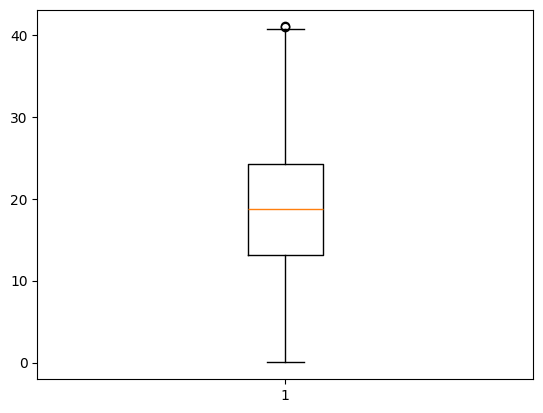

In [26]:
plt.boxplot(tgt_df_fltr['yield'])

(array([ 45.,  84., 164., 216., 301., 220., 177.,  77.,  47.,  16.]),
 array([1.48777896e-02, 4.11592808e+00, 8.21697837e+00, 1.23180287e+01,
        1.64190790e+01, 2.05201293e+01, 2.46211795e+01, 2.87222298e+01,
        3.28232801e+01, 3.69243304e+01, 4.10253807e+01]),
 <BarContainer object of 10 artists>)

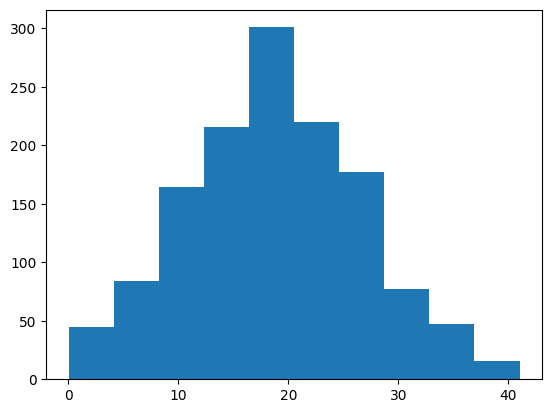

In [58]:
4plt.hist(tgt_df_fltr['yield'])

In [59]:
import scipy.stats as stats

statistic, pvalue = stats.shapiro(tgt_df_fltr['yield'])

print("Статистика:", statistic)
print("p-значение:", pvalue)

Статистика: 0.9960880131717147
p-значение: 0.0016223091631454814


In [29]:
tgt_df_fltr.to_excel('data_check_2.xlsx')

In [30]:
tgt_df_fltr.columns

Index(['season', 'field', 'crop', 'goal_area', 'plant_area', 'prod_weight',
       'region', 'humus', 'ph', 'p2o5', 'k2o', 'yield'],
      dtype='object')

In [31]:
tgt_df_fltr[['yield','humus', 'ph', 'p2o5', 'k2o']].corr()

,yield,humus,ph,p2o5,k2o
yield,1.000000,-0.023058,0.093088,0.163766,0.119586
humus,-0.023058,1.000000,0.125724,-0.243175,0.214297
ph,0.093088,0.125724,1.000000,0.485748,0.588540
p2o5,0.163766,-0.243175,0.485748,1.000000,0.377961
k2o,0.119586,0.214297,0.588540,0.377961,1.000000


In [32]:
tgt_df_fltr.shape

(1347, 12)

In [33]:
tgt_df_fltr['k2o'].value_counts()

k2o
0.00      309
85.80      15
94.60      13
96.80      12
97.90      11
         ... 
164.27      1
215.05      1
150.61      1
208.59      1
155.10      1
Name: count, Length: 393, dtype: int64

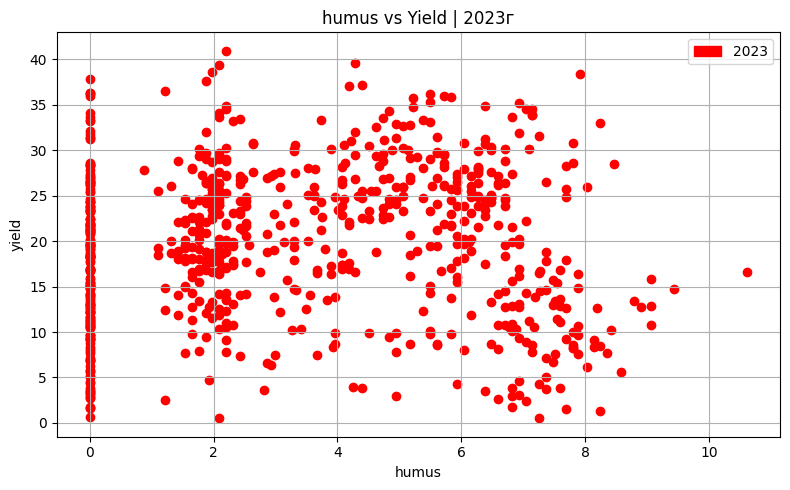

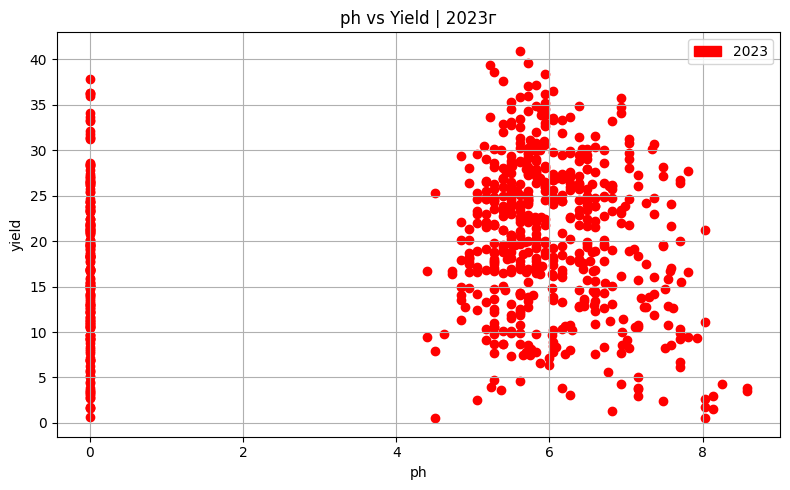

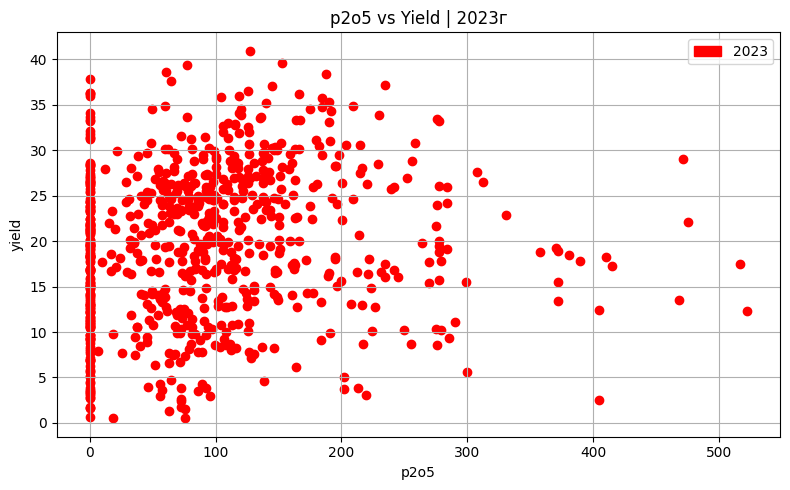

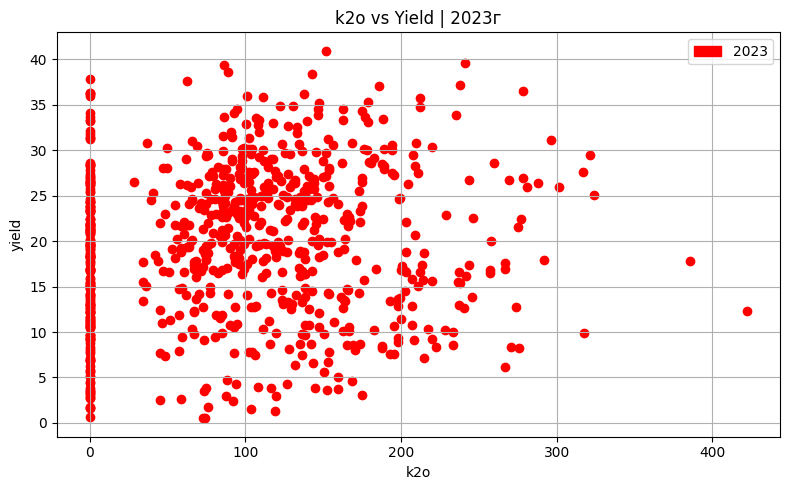

In [55]:
import matplotlib.patches as mpatches

work_columns = ['humus', 'ph', 'p2o5', 'k2o']

for clmn in work_columns:
    test = tgt_df_fltr[tgt_df_fltr['season'] == 2023]
    x = test[clmn]
    y = test['yield']

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, color='red')
    plt.xlabel(clmn)
    plt.ylabel('yield')
    plt.title(f'{clmn} vs Yield | 2023г')

    red_patch = mpatches.Patch(color='red', label='2023')
    plt.legend(handles=[red_patch])

    plt.grid(True)
    plt.tight_layout()
    plt.show()



Детальная статистика модели:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.970
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                     812.0
Date:                Sat, 29 Mar 2025   Prob (F-statistic):           1.29e-57
Time:                        16:06:22   Log-Likelihood:                -98.654
No. Observations:                  80   AIC:                             205.3
Df Residuals:                      76   BIC:                             214.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0144 

ValueError: x and y must be the same size

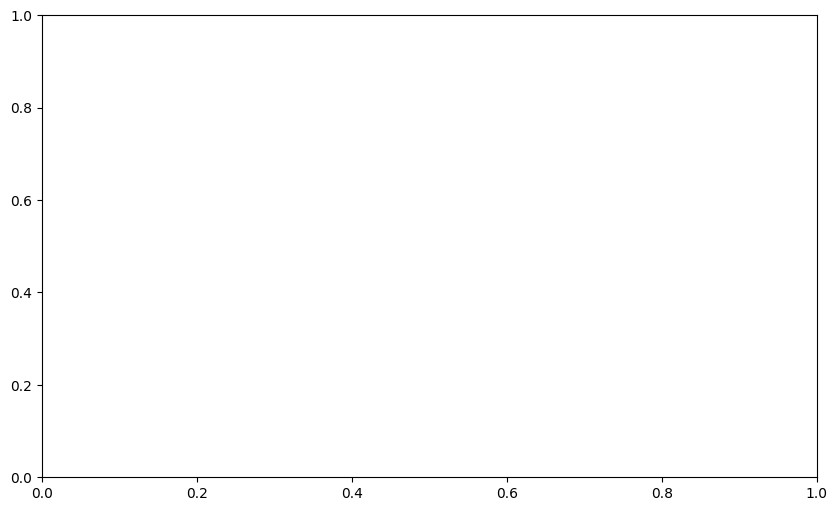

In [60]:
# Импорт необходимых библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm

# 1. Создаем синтетические данные для примера (в реальном проекте загружаете свои данные)
np.random.seed(42)
data = {
    'X1': np.random.rand(100) * 10,
    'X2': np.random.rand(100) * 5,
    'X3': np.random.rand(100) * 2
}
df = pd.DataFrame(data)
df['y'] = 2.5 + 1.5*df['X1'] - 0.8*df['X2'] + 0.3*df['X3'] + np.random.normal(0, 1, 100)

# 2. Разделяем данные на признаки (X) и целевую переменную (y)
X = df[['X1', 'X2', 'X3']]
y = df['y']

# 3. Разделяем на тренировочный и тестовый наборы
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Детальный отчет с помощью statsmodels (с p-значениями)
X_sm = sm.add_constant(X_train)  # добавляем константу для intercept
model_sm = sm.OLS(y_train, X_sm).fit()
print("\nДетальная статистика модели:")
print(model_sm.summary())

# 8. Визуализация
plt.figure(figsize=(10, 6))

# Фактические vs предсказанные значения
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Фактические значения')
plt.ylabel('Предсказанные значения')
plt.title('Фактические vs Предсказанные значения')
plt.show()

# Остатки модели
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Анализ остатков')
plt.show()

In [41]:
f_harvest

,season,field,prod_weight,area
0,2023,02.09.02.002.01,188.94,120.25
1,2023,02.09.02.015.00,44.38,36.34
2,2023,02.09.02.019.00,109.28,50.78
3,2023,02.09.03.032.00,28326.02,105.42
4,2023,02.09.06.004.01,60802.00,56.41
...,...,...,...,...
8874,2024,72.22.10.037.00,1.75,2.85
8875,2024,72.22.10.038.00,168.77,149.58
8876,2024,72.22.10.040.00,3.99,3.26
8877,2024,72.22.10.041.00,59.15,29.78


In [42]:
# Импорт необходимых библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm

# 1. Создаем синтетические данные для примера (в реальном проекте загружаете свои данные)
np.random.seed(42)
data = {
    'X1': np.random.rand(100) * 10,
    'X2': np.random.rand(100) * 5,
    'X3': np.random.rand(100) * 2
}
df = pd.DataFrame(data)
df['y'] = 2.5 + 1.5*df['X1'] - 0.8*df['X2'] + 0.3*df['X3'] + np.random.normal(0, 1, 100)

# 2. Разделяем данные на признаки (X) и целевую переменную (y)
X = df[['X1', 'X2', 'X3']]
y = df['y']

# 3. Разделяем на тренировочный и тестовый наборы
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Детальный отчет с помощью statsmodels (с p-значениями)
X_sm = sm.add_constant(X_train)  # добавляем константу для intercept
model_sm = sm.OLS(y_train, X_sm).fit()
print("\nДетальная статистика модели:")
print(model_sm.summary())

# 8. Визуализация
plt.figure(figsize=(10, 6))

# Фактические vs предсказанные значения
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Фактические значения')
plt.ylabel('Предсказанные значения')
plt.title('Фактические vs Предсказанные значения')
plt.show()

# Остатки модели
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Анализ остатков')
plt.show()


Детальная статистика модели:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.970
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                     812.0
Date:                Sat, 29 Mar 2025   Prob (F-statistic):           1.29e-57
Time:                        14:14:35   Log-Likelihood:                -98.654
No. Observations:                  80   AIC:                             205.3
Df Residuals:                      76   BIC:                             214.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0144 

NameError: name 'y_pred' is not defined

<Figure size 1000x600 with 0 Axes>

# Гипотезы
1. Глубина почвообработки влияет на урожайность
2. Происхождение семян влияет на урожайность
3. Технология выращивания влияет на урожайность

**!!! ВНИМАНИЕ !!! для предварительной проверки гипотез беру только "Кукуруза силос"**

In [43]:
tgt_id = f_plant_x_harvest_id[f_plant_x_harvest_id['crop'] == 'Кукуруза силос'] \
    .merge(
        f_plant[f_plant['area'].between(f_plant['goal_area']*0.98, f_plant['goal_area']*1.02)][['field', 'season', 'area']], 
        how='inner', 
        on=['field', 'season']
    )
tgt_id.head(3)

,season,field,crop,goal_area,area
0,2023,22.47.05.004.00,Кукуруза силос,316.08,316.08
1,2023,22.47.05.005.00,Кукуруза силос,365.03,365.03
2,2023,22.47.10.002.00,Кукуруза силос,152.97,152.97


In [44]:
# чуть срезал кол-во из-за перезасева (125)
tgt_id.shape

(1436, 5)

## Виды почвообработки влияют на урожайность

In [45]:
land_works = works_ish[works_ish['work_type'] == 'Обработка почвы'] \
    [['season', 'field', 'work_subtype']] 
land_works['cnt'] = 1

land_works = land_works.pivot_table(index=['season', 'field'], columns=['work_subtype'], values=['cnt']) \
    .reset_index()

# убираем уровни
lst = []
for a, b in land_works.columns:
    if a == 'cnt':
        lst.append(b)
    else:
        lst.append(a)      
land_works.columns = lst

land_works.fillna(0, inplace=True)


df = tgt_id \
    .merge(
        land_works,
        how='inner',
        on=['season', 'field']
    ) \
    .merge(
        f_harvest[['season', 'field', 'prod_weight']],
        how='inner',
        on=['season', 'field']
    )
df['target'] = df['prod_weight'] / df['area']

In [48]:
fields_ish.head(3)
tgt_id.head(3)

,season,field,crop,goal_area,area
0,2023,22.47.05.004.00,Кукуруза силос,316.08,316.08
1,2023,22.47.05.005.00,Кукуруза силос,365.03,365.03
2,2023,22.47.10.002.00,Кукуруза силос,152.97,152.97


In [49]:
df['target'].quantile(0.99)

np.float64(43.657668008651214)

{'whiskers': [<matplotlib.lines.Line2D at 0x16ea0be60>,
 'caps': [<matplotlib.lines.Line2D at 0x16ea0a270>,
 'boxes': [<matplotlib.lines.Line2D at 0x16ea0a5d0>],
 'medians': [<matplotlib.lines.Line2D at 0x16ea09a30>],
 'fliers': [<matplotlib.lines.Line2D at 0x16ea081d0>],
 'means': []}

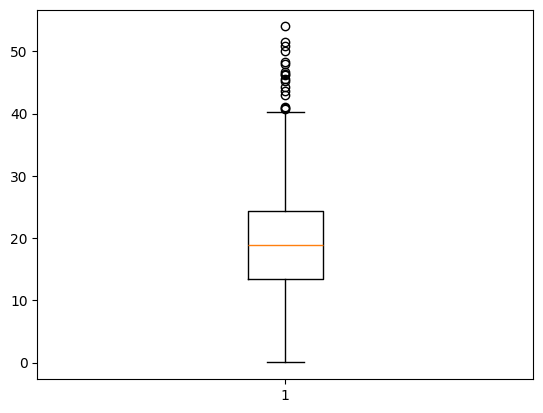

In [52]:
df = tgt_id \
    .merge(
        f_harvest[['season', 'field', 'prod_weight']],
        how='inner',
        on=['season', 'field']
    ) \
    .merge(
        fields_ish[['season', 'field', 'humus', 'ph', 'p2o5', 'k2o']],
        how='inner',
        on=['season', 'field']
    )

df['target'] = df['prod_weight'] / df['area']
df = df[(df['target'] < df['target'].quantile(0.92)) & (df['target'] > 0)]

plt.boxplot(df['target'])

In [53]:
# регрессия
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Читаем данные из файла
data = df.copy()

# Выбираем столбцы для X и y
X = data[['humus', 'ph', 'p2o5', 'k2o']]
y = data['target']

# Создаем объект модели линейной регрессии
model = LinearRegression()

# Обучаем модель на данных
model.fit(X, y)

# Выводим коэффициенты и свободный член
print(f'Коэффициенты: {model.coef_}')
print(f'Свободный член: {model.intercept_}')


# Используем уже обученную модель и известные данные
y_true = data['target']  # Истинные значения y
y_pred = model.predict(X)  # Предсказанные значения y

# Коэффициент детерминации R²
r2 = r2_score(y_true, y_pred)
print(f'Коэффициент детерминации (R²): {r2:.4f}')

Коэффициенты: [ 0.00039339 -0.04446904  0.00964253  0.00895931]
Свободный член: 17.875024476583924
Коэффициент детерминации (R²): 0.0202


In [56]:
?plt.scatter

Signature:
plt.scatter(
    x,
    y,
    s=None,
    c=None,
    marker=None,
    cmap=None,
    norm=None,
    vmin=None,
    vmax=None,
    alpha=None,
    linewidths=None,
    *,
    edgecolors=None,
    plotnonfinite=False,
    data=None,
    **kwargs,
)
Docstring:
A scatter plot of *y* vs. *x* with varying marker size and/or color.

Parameters
----------
x, y : float or array-like, shape (n, )
    The data positions.

s : float or array-like, shape (n, ), optional
    The marker size in points**2.
    Default is ``rcParams['lines.markersize'] ** 2``.

c : array-like or list of colors or color, optional
    The marker colors. Possible values:

    - A scalar or sequence of n numbers to be mapped to colors using
      *cmap* and *norm*.
    - A 2D array in which the rows are RGB or RGBA.
    - A sequence of colors of length n.
    - A single color format string.

    Note that *c* should not be a single numeric RGB or RGBA sequence
    because that is indistinguishable from an arra

In [75]:
df[df['humus'] == 0].shape

(302, 11)

In [77]:
df.shape

(1196, 11)

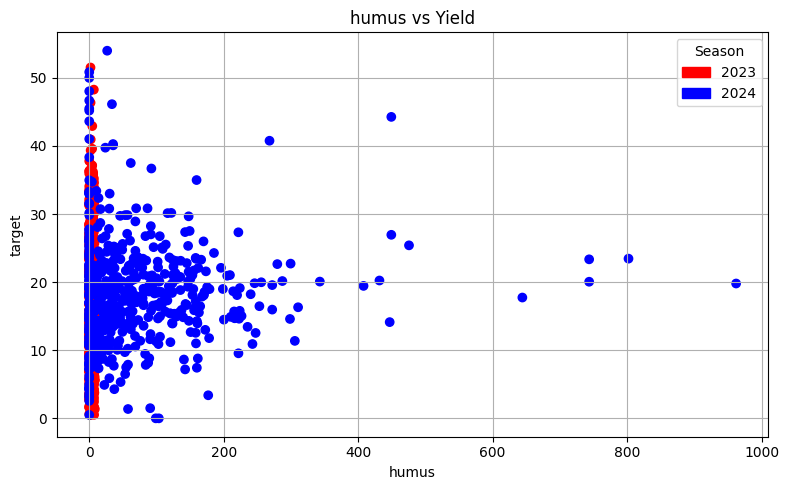

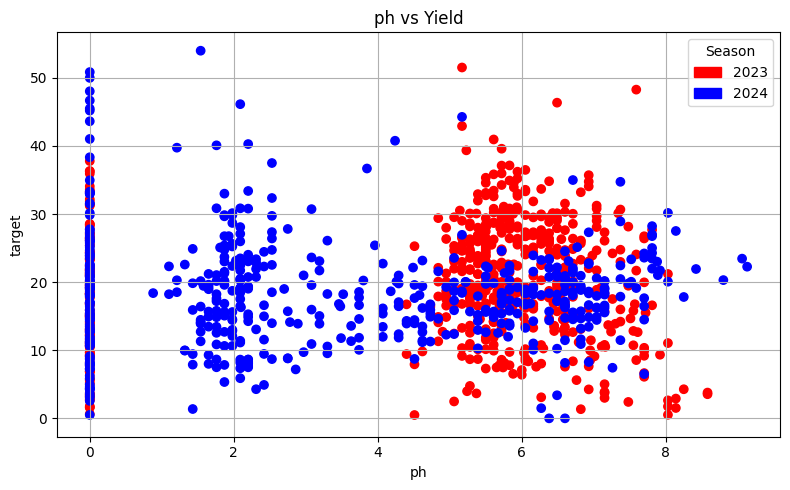

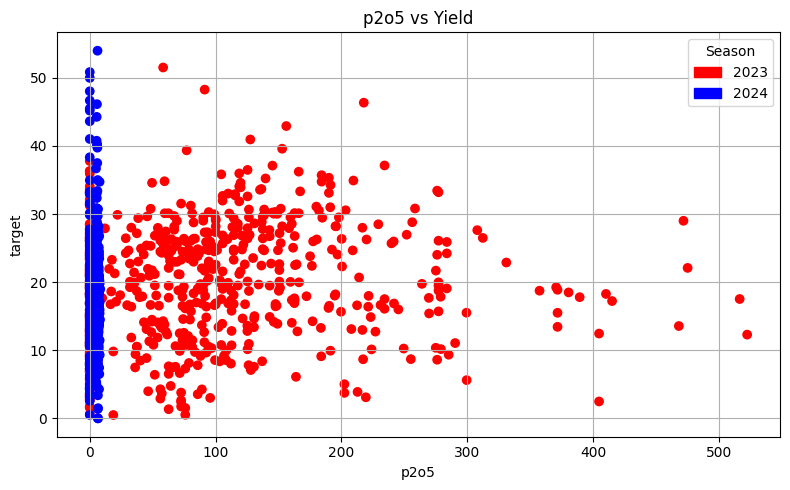

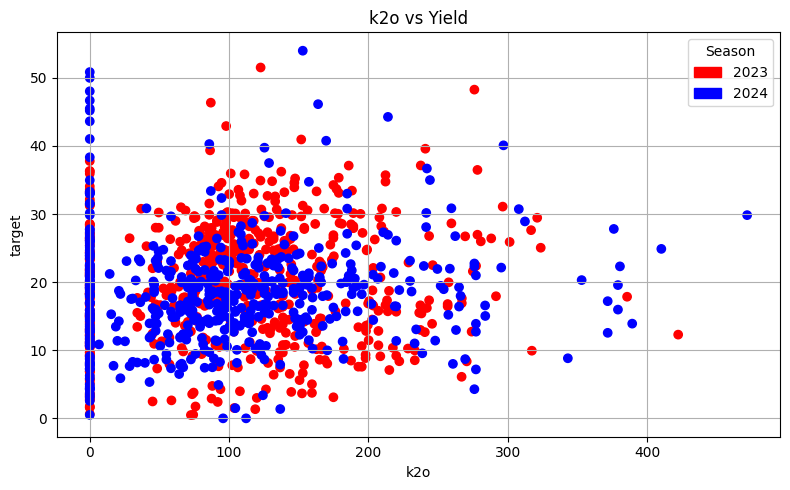

In [56]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

work_columns = ['humus', 'ph', 'p2o5', 'k2o']

color_map = {2023: 'red', 2024: 'blue'}
legend_patches = [mpatches.Patch(color=color, label=str(year)) for year, color in color_map.items()]

for clmn in work_columns:
    x = df[clmn]
    y = df['target']
    c = df['season'].map(color_map)

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, c=c)
    plt.xlabel(clmn)
    plt.ylabel('target')
    plt.title(f'{clmn} vs Yield')
    plt.legend(handles=legend_patches, title="Season")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [55]:
works_ish[(works_ish['prod_weight'] > 0) & (works_ish['work_type'] == 'Уборка')][]

,season,field,work_type,work_subtype,start_date,end_date,area,main_tech,add_tech,mech,proc_depth,prod_purpose,prod_weight,prod_dry_perc,prod_humid,prod_impur,yield_fact,work_id
5322,2023,54.17.01.041.00,Уборка,Уборка трав,2022-09-05,2022-09-05,24.00,"Комбайн зерноуборочный John Deere W540, гос.но...",NaN,Ковалев Андрей Анатольевич,NaN,товарная,7.08,NaN,13.8,30.0,0.29,66DB7627-50DA-47D5-8F3C-1AF33BFE37C7
5323,2023,54.17.01.041.00,Уборка,Уборка трав,2022-09-05,2022-09-05,24.00,"Косилка самоходная John Deere R450, гос.ном. 8...",NaN,Мальцев Михаил Михайлович,NaN,товарная,7.08,NaN,13.8,30.0,0.29,62440F7D-4F4F-4D41-B2E5-A10D8EF95F75
5324,2023,54.17.03.042.01,Уборка,Уборка трав,2022-09-05,2022-09-05,10.00,"Комбайн зерноуборочный John Deere 9640, гос.но...",NaN,Титов Александр Владимирович,NaN,товарная,2.01,NaN,16.6,38.0,0.20,3C8E4C69-DEC2-46AF-9F01-1715CCF1CE6D
28414,2023,36.02.03.016.00,Уборка,Вывоз,2023-05-05,2023-06-05,20.30,"Комбайн кормоуборочный John Deere 8500, гос.но...","Подборщик John Deere 649, инв.ном. 20200244, з...",Варганов Эдуард Александрович,NaN,сенаж,88.99,43.0,NaN,NaN,1.88,BD21E1FF-0BAF-4A53-848B-F18F74315EE5
32805,2023,36.02.06.008.01,Уборка,Вывоз,2023-05-11,2023-05-14,71.83,Арендованная техника,NaN,Автайкин Петр Григорьевич,NaN,сенаж,492.39,32.0,NaN,NaN,2.19,1AA8B955-60B1-4A91-B31E-39D7E6A3F505
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174675,2024,40.17.06.004.00,Уборка,Прямое комбайнирование,2024-10-27,2024-10-27,78.06,"Комбайн зерноуборочный Ростсельмаш Acros 560, ...","Жатка кукурузная Geringhoff RD 800B, зав.ном. ...",Пашкаускас Андрей Аркадьевич,NaN,товарная,569.10,NaN,29.0,30.0,7.29,815761F0-8AFA-45AB-B728-6321155C7B63
174676,2024,40.23.08.010.00,Уборка,Вывоз,2024-10-27,2024-10-27,50.00,"Погрузчик фронтальный Telemaxagri TMA 650B, го...",NaN,Нефёдкин Евгений Иванович,NaN,солома,7.18,90.0,NaN,NaN,0.13,45190065-860B-4505-8153-17596B7C655C
174677,2024,54.17.12.029.00,Уборка,Вывоз,2024-10-27,2024-10-27,27.00,"Трактор колесный Птз К-746М, зав.ном. KR000035...",NaN,Абраменко Михаил Александрович,NaN,NaN,77.88,27.0,NaN,NaN,0.78,D916E6B9-3D8E-437C-B0E5-9E59F2287887
174679,2024,54.28.13.038.00,Уборка,Вывоз,2024-10-27,2024-10-27,7.00,"Трактор колесный Lovol 2604, зав.ном. M700060R...",Арендованная техника,Лагунов Юрий Николаевич,NaN,солома,9.45,85.0,NaN,NaN,1.15,63C37AF5-60EC-492A-A396-CA750B656725


In [23]:
df[['season', 'field','Боронование','Вспашка', 'Глубокорыхление', 'Дискование', 'Культивация',
'Междурядная обработка без внесения', 'Мульчирование', 'Прикатывание',
'Уборка камней', 'target']].to_csv('Данные о видах почвообработки.csv', encoding='windows-1251')

In [24]:
df[['season', 'field','Боронование','Вспашка', 'Глубокорыхление', 'Дискование', 'Культивация',
'Междурядная обработка без внесения', 'Мульчирование', 'Прикатывание',
'Уборка камней', 'target']].corr()

ValueError: could not convert string to float: '22.47.05.004.00'

In [ ]:
# регрессия
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Читаем данные из файла
data = df.copy()

# Выбираем столбцы для X и y
X = data[['Боронование','Вспашка', 'Глубокорыхление', 'Дискование', 'Культивация',
'Междурядная обработка без внесения', 'Мульчирование', 'Прикатывание',
'Уборка камней']]
y = data['target']

# Создаем объект модели линейной регрессии
model = LinearRegression()

# Обучаем модель на данных
model.fit(X, y)

# Выводим коэффициенты и свободный член
print(f'Коэффициенты: {model.coef_}')
print(f'Свободный член: {model.intercept_}')


# Используем уже обученную модель и известные данные
y_true = data['target']  # Истинные значения y
y_pred = model.predict(X)  # Предсказанные значения y

# Коэффициент детерминации R²
r2 = r2_score(y_true, y_pred)
print(f'Коэффициент детерминации (R²): {r2:.4f}')

In [ ]:
work_columns = ['Боронование','Вспашка', 'Глубокорыхление', 'Дискование', 'Культивация',
'Междурядная обработка без внесения', 'Мульчирование', 'Прикатывание',
'Уборка камней']

for clmn in work_columns:
    x = df[clmn]
    y = df['target']
    plt.scatter(x, y)
    plt.show()

In [ ]:
df.columns

In [ ]:
['Боронование','Вспашка', 'Глубокорыхление', 'Дискование', 'Культивация',
'Междурядная обработка без внесения', 'Мульчирование', 'Прикатывание',
'Уборка камней','target']

In [ ]:
df.head(30)

In [ ]:
lst = []
for a, b in [('season',                                   ''),
( 'field',                                   ''),
(   'cnt',                        'Боронование'),
(   'cnt',                            'Вспашка'),
(   'cnt',                    'Глубокорыхление'),
(   'cnt',                         'Дискование'),
(   'cnt',                        'Культивация'),
(   'cnt', 'Междурядная обработка без внесения'),
(   'cnt',                      'Мульчирование'),
(   'cnt',                       'Прикатывание'),
(   'cnt',                      'Уборка камней')]:

    if a == 'cnt':
        lst.append(b)
    else:
        lst.append(a)

lst

In [ ]:
?pd.DataFrame.pivot_table

In [ ]:
# на одном поле в одном сезоне производили работы на одном уровне?
works_ish[works_ish['work_type'] == 'Обработка почвы'] \
    .groupby(['season', 'field'], as_index=False) \
    .agg({'proc_depth':['min', 'max']})

In [ ]:
works_ish[works_ish['work_type'] == 'Обработка почвы']['work_subtype'].unique()

In [ ]:
works_ish[works_ish['work_type'] == 'Обработка почвы']['work_subtype'].value_counts()

In [ ]:
f_plant_x_harvest_id['crop'].value_counts().describe()

In [ ]:
?pd.Series.between

In [ ]:
8318 - 6854

In [ ]:
# среди двух сезонов одинаковое кол-во полей с которых собран урожай
f_unique.merge(f_harvest, how='left', on=['field', 'season']) \
    .groupby('season', as_index=False) \
    .agg({'prod_weight':'count'})

In [ ]:
# среди двух сезонов одинаковое кол-во полей с которых собран урожай
f_unique.merge(f_harvest, how='left', on=['field', 'season']) \
    .groupby('crop', as_index=False) \
    .agg({'prod_weight':'count'}) \
    .head(30)

In [ ]:
works_ish[(works_ish['prod_weight'] > 0)]['work_type'].value_counts()

# Гипотезы
1. Глубина почвообработки влияет на урожайность
2. Происхождение семян влияет на урожайность
3. Технология выращивания влияет на урожайность

## Глубина почвообработки влияет на урожайность

In [ ]:
# находим глубину почвообработки
works_ish[works_ish['work_type'] == 'Обработка почвы'].duplicated().sum()


# есть пустые значения

In [ ]:
depth_h = fields_ish \
    .merge(
        works_ish[works_ish['work_type'] == 'Обработка почвы'].copy().rename(columns={'area':'works_area', 'yield_fact':'yield_fact_inc§'}),
        how='left',
        on=['field', 'season']
    ) \
    .merge(
        works_ish[(works_ish['yield_fact'] > 0) & (works_ish['work_type'] == 'Уборка')] \
            .groupby(['season', 'field'], as_index=False) \
            .agg({'yield_fact':'sum'}),
        how='left',
        on=['field', 'season']
    )

# есть полные дубли - удаляем
depth_h.drop_duplicates(inplace=True)
depth_h.drop(columns=['Unnamed: 18'], inplace=True)

# оставляем столбцы
depth_h_data = depth_h[[
    'field', 'season', 'land_type', 'crop', 'yield_plan',
    'work_type', 'work_subtype', 'proc_depth', 'yield_fact'
]].copy()

# 
depth_h_data.head(3)

In [ ]:
df = depth_h_data[depth_h_data[['work_type', 'work_subtype', 'proc_depth']].isna().sum(axis=1) == 0].copy()

df.head(3)

In [ ]:
df['yield_fact'].isna().sum()

In [ ]:
depth_h.columns